# Stage 8: Retrieval evaluation

40 questions with an answer key written by reading the handbook (`evals/handbook_eval.jsonl`):
the 11 earlier spot-check questions with a known answer, re-keyed by reading, plus 29 new ones of three kinds:
- **reworded**: everyday wording that avoids the handbook's own terms;
- **multi-section**: the answer needs 2-3 sections of one article;
- **multi-article**: the answer needs 2-3 articles.

Each question lists its **evidence** as verbatim quotes. Quotes are mapped to the chunk(s) that contain them by
string matching, never by search, so the key doesn't depend on the system under test. Code:
`src/handbook_qa/evaluation.py`.

**Score (chunk recall@k):** a question's *expected chunks* are the distinct chunks its quotes live in (several
quotes in one chunk count once; an image record counts the same as the chunk holding its description). Its score is
the fraction of expected chunks found in the top k; the table shows the mean over questions. Reported at k = 5
(what the app passes on after reranking) and k = 10.

One question (A-09) was replaced during review: the subagent's version was labelled multi-section but all its
evidence fell in one chunk.

**Methods:** dense only, BM25 only, fused (dense + BM25 with RRF, no reranker), and fused + a cross-encoder
(top 30 fused candidates rescored). bge-reranker-v2-m3 is left out: ~45 s per question on this laptop.

**Time per question** is wall time for one query, excluding model loading.

In [1]:
import collections
import json
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from handbook_qa import evaluation as ev
from handbook_qa.config import ROOT, load_settings
from handbook_qa.retrieval import Reranker, Retriever

settings = load_settings()
EVAL_SET = ROOT / "evals" / "handbook_eval.jsonl"
KS = (5, 10)
RERANKERS = ["Xenova/ms-marco-MiniLM-L-6-v2", "jinaai/jina-reranker-v1-turbo-en"]
pd.set_option("display.max_colwidth", 100)

retriever = Retriever.from_settings(replace(settings, retrieval=replace(settings.retrieval, rerank=False)))
retriever.rerank_candidates = settings.retrieval.rerank_candidates
questions = ev.load_eval_set(EVAL_SET)
print(len(questions), "questions;", dict(collections.Counter(q.type for q in questions)))

C:\Users\shaba\Documents\extra project\paradigm_assessment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


40 questions; {'existing': 11, 'reworded': 9, 'multi-section': 8, 'multi-article': 12}


## The answer key resolves to chunks

Every quote must be found in at least one chunk of its article. If chunking changes, this is recomputed.

In [2]:
problems = ev.resolve(questions, retriever.items)
print("problems:", problems or "none")
evidence_counts = collections.Counter(len(q.evidence) for q in questions)
articles_per_q = collections.Counter(len({e.article for e in q.evidence}) for q in questions)
chunks_per_q = collections.Counter((q.type, len(ev.expected_chunks(q))) for q in questions)
print("evidence quotes per question:", dict(sorted(evidence_counts.items())))
print("distinct articles per question:", dict(sorted(articles_per_q.items())))
print("expected chunks in total:", sum(len(ev.expected_chunks(q)) for q in questions))
pd.DataFrame([{"type": t, "expected chunks": n, "questions": c} for (t, n), c in sorted(chunks_per_q.items())]) \
    .pivot(index="type", columns="expected chunks", values="questions").fillna(0).astype(int)

problems: none
evidence quotes per question: {1: 1, 2: 3, 3: 5, 4: 13, 5: 5, 6: 6, 7: 4, 8: 1, 9: 1, 10: 1}
distinct articles per question: {1: 27, 2: 12, 3: 1}
expected chunks in total: 80


expected chunks,1,2,3,4
type,,,,
existing,4,2,4,1
multi-article,0,8,4,0
multi-section,0,7,1,0
reworded,7,2,0,0


In [3]:
pd.DataFrame([{"id": q.id, "type": q.type, "question": q.question, "quotes": len(q.evidence),
               "articles": len({e.article for e in q.evidence}),
               "expected chunks": " | ".join(" or ".join(sorted(loc)) for loc in ev.expected_chunks(q))}
              for q in questions])

,id,type,question,quotes,articles,expected chunks
0,A-01,existing,Which communication channels are best and worst at PostHog?,4,2,company/brand-assets#04 or img-p0041-x258 | company/communication#01 | company/communication#07
1,A-02,existing,What is the policy for spending company money?,6,1,people/spending-money#01 | people/spending-money#02
2,A-03,existing,What are the stages of the engineering hiring process?,4,1,people/hiring-process/engineering-hiring#01 | people/hiring-process/engineering-hiring#02 | peop...
3,A-04,existing,What should the logo never look like?,6,1,company/brand-assets#02 | company/brand-assets#02 or img-p0038-x244 | company/brand-assets#01
4,A-05,reworded,Do I need my manager to sign off before I take a week of vacation?,3,1,people/time-off#01 | people/time-off#02
5,A-06,reworded,"If I eventually leave to found my own startup, would PostHog put money into it?",1,1,people/benefits#02
6,A-07,reworded,Are there days of the week when I shouldn't book calls with my teammates?,3,1,getting-started/meetings#01 | getting-started/meetings#02
7,A-08,multi-section,"Can I take on paid freelance work outside PostHog, and what do I need to watch out for?",4,1,people/side-gigs#01 | people/side-gigs#02
8,A-09,multi-section,"I've just been made lead of a small team. Am I now my teammates' manager, who decides what we wo...",5,1,company/small-teams#02 | company/small-teams#03 | company/small-teams#04
9,A-10,multi-article,"I'm flying abroad for my team's offsite. Which budget should my travel go on, do I need to buy t...",5,2,people/spending-money#03 | people/spending-money#08 | company/offsites#06


## Run every method

In [4]:
methods = {"dense only": ev.dense_only(retriever), "BM25 only": ev.bm25_only(retriever),
           "fused (no rerank)": ev.fused(retriever)}
rows = ev.run(questions, methods, KS)
for name in RERANKERS:
    retriever.reranker = Reranker(name, settings.embed.model_cache, settings.embed.threads)
    label = "fused + " + name.split("/")[1]
    rows += ev.run(questions, {label: ev.reranked(retriever)}, KS)
retriever.reranker = None
results = pd.DataFrame(rows)

## Results

In [5]:
order = list(dict.fromkeys(results["method"]))
summary = results.groupby("method", sort=False).agg(
    **{f"chunk recall@{k}": (f"recall@{k}", "mean") for k in KS},
    **{f"all chunks@{k}": (f"recall@{k}", lambda s: (s == 1).mean()) for k in KS},
    **{"median s / question": ("seconds", "median"), "p90 s / question": ("seconds", lambda s: s.quantile(0.9))},
).loc[order]
summary.round(3)

,chunk recall@5,chunk recall@10,all chunks@5,all chunks@10,median s / question,p90 s / question
method,,,,,,
dense only,0.662,0.733,0.500,0.600,0.061,0.081
BM25 only,0.612,0.696,0.400,0.500,0.002,0.004
fused (no rerank),0.671,0.779,0.500,0.650,0.065,0.091
fused + ms-marco-MiniLM-L-6-v2,0.733,0.846,0.575,0.750,2.850,2.936
fused + jina-reranker-v1-turbo-en,0.681,0.796,0.525,0.675,3.679,3.801


`chunk recall@k`: mean over questions of the fraction of expected chunks found in the top k.
`all chunks@k`: share of questions with *all* their expected chunks in the top k.
Times: wall time per question, excluding model loading.

Recall by question type, at k = 5:

In [6]:
by_type = results.pivot_table(index="type", columns="method", values="recall@5", aggfunc="mean")[order]
by_type.insert(0, "questions", results[results["method"] == order[0]].groupby("type").size())
by_type.round(2)

method,questions,dense only,BM25 only,fused (no rerank),fused + ms-marco-MiniLM-L-6-v2,fused + jina-reranker-v1-turbo-en
type,,,,,,
existing,11,0.82,0.82,0.91,0.94,0.89
multi-article,12,0.58,0.51,0.51,0.61,0.62
multi-section,8,0.88,0.48,0.71,0.71,0.69
reworded,9,0.39,0.61,0.56,0.67,0.50


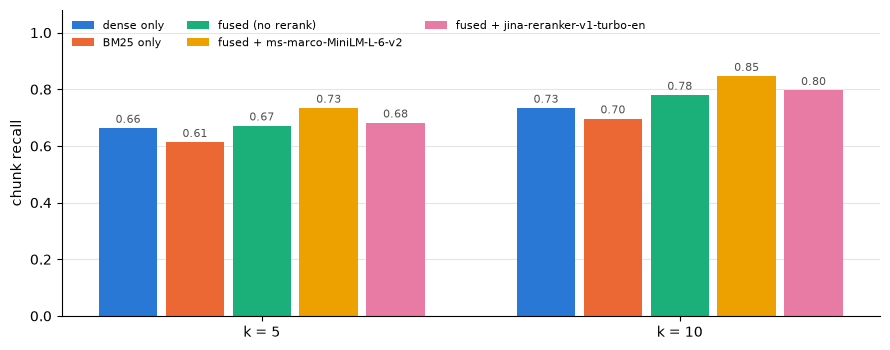

In [7]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(KS))
width = 0.16
for n, method in enumerate(order):
    values = [summary.loc[method, f"chunk recall@{k}"] for k in KS]
    bars = ax.bar(x + (n - 2) * width, values, width - 0.02, color=SERIES[n], label=method)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color="#52514e", padding=2)
ax.set_xticks(x, [f"k = {k}" for k in KS])
ax.set_ylim(0, 1.08)
ax.set_ylabel("chunk recall")
ax.legend(frameon=False, fontsize=8, ncols=3, loc="upper left")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()

## Where methods miss

Questions where some method found less than all of the evidence at k = 5.

In [8]:
per_q = results.pivot_table(index="id", columns="method", values="recall@5")[order]
text = {q.id: q.question for q in questions}
misses = per_q[(per_q < 1).any(axis=1)].copy()
misses.insert(0, "question", [text[i] for i in misses.index])
misses.round(2)

method,question,dense only,BM25 only,fused (no rerank),fused + ms-marco-MiniLM-L-6-v2,fused + jina-reranker-v1-turbo-en
id,,,,,,
A-01,Which communication channels are best and worst at PostHog?,0.33,0.33,0.33,0.33,0.33
A-02,What is the policy for spending company money?,0.50,1.00,1.00,1.00,1.00
A-06,"If I eventually leave to found my own startup, would PostHog put money into it?",0.00,1.00,1.00,0.00,1.00
A-07,Are there days of the week when I shouldn't book calls with my teammates?,0.50,0.50,0.00,1.00,0.50
A-08,"Can I take on paid freelance work outside PostHog, and what do I need to watch out for?",1.00,0.00,0.00,0.50,0.00
A-09,"I've just been made lead of a small team. Am I now my teammates' manager, who decides what we wo...",1.00,0.33,0.67,0.67,1.00
A-10,"I'm flying abroad for my team's offsite. Which budget should my travel go on, do I need to buy t...",0.67,1.00,0.67,0.67,1.00
A-11,Someone texted me pretending to be James and asking me to buy gift cards urgently. What should I...,0.50,0.50,0.50,0.50,0.50
A-12,"I'm thinking about quitting. How much notice do I give, who do I tell, and do I have to send bac...",0.67,0.33,0.33,0.33,0.67
